# Pregunta 3 — YOLO sobre Caltech Camera Traps (CCT-20) · Notebook de Colab

Este notebook **solo orquesta**: la lógica está en los módulos `.py` de la carpeta `codigo/` de tu Drive.

**Antes de empezar**
1. Entorno de ejecución → *Cambiar tipo de entorno de ejecución* → **GPU (T4)**.
2. En tu Drive debe existir:
```
MyDrive/POSGRADO_IA/2026_2/REDES_NEURONALES/EXAMEN_PARCIAL/P03/yolo_data_cct20.zip      (lo generó preparar_local.py en tu PC)
MyDrive/POSGRADO_IA/2026_2/REDES_NEURONALES/EXAMEN_PARCIAL/P03/codigo/                  colab_comun.py, entrenar.py, evaluar.py, robustez.py, gradcam_cct.py, monitoreo.py
```
3. Ejecuta las celdas en orden. Todo lo que se produce (pesos, tablas, figuras) queda en `MyDrive/POSGRADO_IA/2026_2/REDES_NEURONALES/EXAMEN_PARCIAL/P03/resultados/`.

**Si Colab se desconecta:** vuelve a ejecutar desde la celda 1. La preparación de datos se repite (el disco de Colab es temporal), pero el entrenamiento **se omite si ya terminó** y **se reanuda si quedó a medias**.

In [16]:
# 1. Configuración (edita solo esta celda)
DRIVE_BASE  = "/content/drive/MyDrive/POSGRADO_IA/2026_2/REDES_NEURONALES/EXAMEN_PARCIAL/P03"
EXPERIMENTO = "B_strong"          # "A_base" | "B_strong" | "C_strong_os3"  (ablación del informe)
WEIGHTS     = "yolov8s.pt"        # preentrenado (se descarga solo; o ponlo junto al código en Drive)
IMGSZ, EPOCHS, BATCH, PATIENCE = 640, 50, 32, 15
TRAIN_FRACTION = 1.0              # 1.0 = todo el train
RETRAIN     = False               # True = forzar un entrenamiento nuevo (la corrida anterior se conserva renombrada)

In [17]:
import os
from google.colab import drive
drive.mount("/content/drive", force_remount=True)   # refresca el listado de Drive

print("DRIVE_BASE en uso:", DRIVE_BASE)
print("existe la carpeta base:", os.path.exists(DRIVE_BASE))
if os.path.exists(DRIVE_BASE):
    print("contenido de P03:", os.listdir(DRIVE_BASE))
cod = f"{DRIVE_BASE}/codigo"
print("existe codigo/:", os.path.exists(cod))
if os.path.exists(cod):
    print("contenido de codigo/:", os.listdir(cod))

Mounted at /content/drive
DRIVE_BASE en uso: /content/drive/MyDrive/POSGRADO_IA/2026_2/REDES_NEURONALES/EXAMEN_PARCIAL/P03
existe la carpeta base: True
contenido de P03: ['P3_colab.ipynb', 'yolo_data_cct20.zip', 'codigo']
existe codigo/: True
contenido de codigo/: ['LEEME_colab.md', 'monitoreo.py', 'gradcam_cct.py', 'evaluar.py', 'colab_comun.py', 'robustez.py', 'entrenar.py']


In [20]:
import importlib, sys
importlib.invalidate_caches()
sys.path_importer_cache.clear()
sys.path.insert(0, f"{DRIVE_BASE}/codigo")
import colab_comun
print("colab_comun cargado desde:", colab_comun.__file__)

colab_comun cargado desde: /content/drive/MyDrive/POSGRADO_IA/2026_2/REDES_NEURONALES/EXAMEN_PARCIAL/P03/codigo/colab_comun.py


In [21]:
# 2. Dependencias, Drive y módulos
%pip install -q ultralytics
from google.colab import drive
drive.mount("/content/drive")

import sys, importlib
sys.path.insert(0, f"{DRIVE_BASE}/codigo")
import colab_comun as C, entrenar, evaluar, robustez, gradcam_cct, monitoreo
for m in (C, entrenar, evaluar, robustez, gradcam_cct, monitoreo):
    importlib.reload(m)                      # recarga si editaste un .py en Drive

cfg = C.crear_config(DRIVE_BASE=DRIVE_BASE, WEIGHTS=WEIGHTS, IMGSZ=IMGSZ, EPOCHS=EPOCHS, BATCH=BATCH,
                     PATIENCE=PATIENCE, TRAIN_FRACTION=TRAIN_FRACTION, RETRAIN=RETRAIN)
C.info_gpu()
print("device:", cfg.DEVICE, "| experimento:", C.nombre_exp(cfg, EXPERIMENTO))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Tesla T4, 15360 MiB
device: 0 | experimento: yolov8s_B_strong


## 3. Preparar los datos
Copia el zip de Drive al disco local de Colab, lo descomprime, regenera los `.yaml` con la ruta correcta y **verifica los conteos contra la Tabla 1** (cada partición debe decir `OK`). Tarda unos minutos.

In [22]:
# 3. Datos
tabla1 = C.preparar_datos(cfg)
tabla1

Copiando 3.68 GiB de Drive al disco local ...
  copiado en 1.1 min. Descomprimiendo ...
  20000/97578 archivos
  40000/97578 archivos
  60000/97578 archivos
  80000/97578 archivos
  listo en 1.6 min
Verificación contra la Tabla 1:
  train       imágenes= 22487 etiquetas= 22487 esperado= 22487  OK
  val_cis     imágenes=  2775 etiquetas=  2775 esperado=  2775  OK
  val_trans   imágenes= 10638 etiquetas= 10638 esperado= 10638  OK
  test_cis    imágenes=  2859 etiquetas=  2859 esperado=  2859  OK
  test_trans  imágenes= 10027 etiquetas= 10027 esperado= 10027  OK


,imagenes,con_animal,ubicaciones,especies
split,,,,
test_cis,2859,2653,10,14
test_trans,10027,9405,5,14
train,22487,20783,10,15
val_cis,2775,2555,10,14
val_trans,10638,9473,5,12


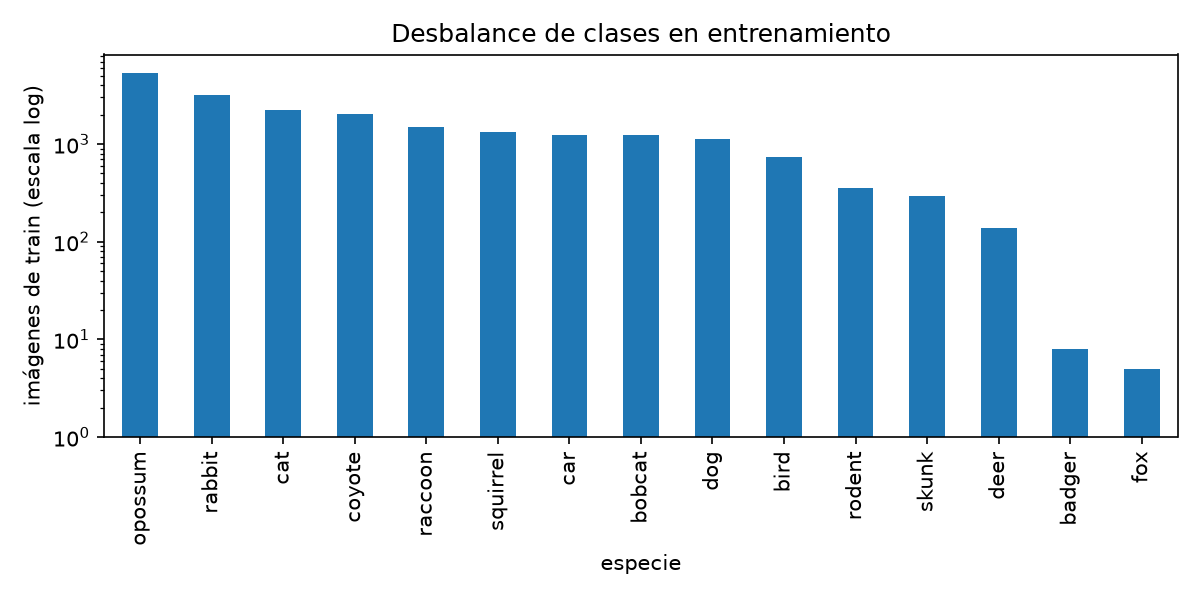

In [23]:
# Figura de desbalance de clases (viene dentro del zip)
from IPython.display import Image, display
display(Image(str(cfg.DATA / "desbalance.png")))

## 4. Entrenamiento
`entrenar.entrenar` decide solo qué hacer:
- corrida **terminada** en Drive → se omite y devuelve sus pesos;
- corrida **cortada** (last.pt) → se **reanuda**;
- no hay nada (o `RETRAIN=True`) → entrena desde los pesos preentrenados.

Para la ablación del informe, cambia `EXPERIMENTO` en la celda 1 (`A_base`, `B_strong`, `C_strong_os3`) y repite desde la celda 4.

In [24]:
# 4. Entrenar (o reutilizar / reanudar)
BEST = entrenar.entrenar(cfg, EXPERIMENTO)
print("BEST =", BEST)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Experimento yolov8s_B_strong: estado previo = nuevo
Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.3, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/cct/yolo_data/train_B_strong.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=

Curvas guardadas en /content/drive/MyDrive/POSGRADO_IA/2026_2/REDES_NEURONALES/EXAMEN_PARCIAL/P03/resultados/tablas/curvas_yolov8s_B_strong.png


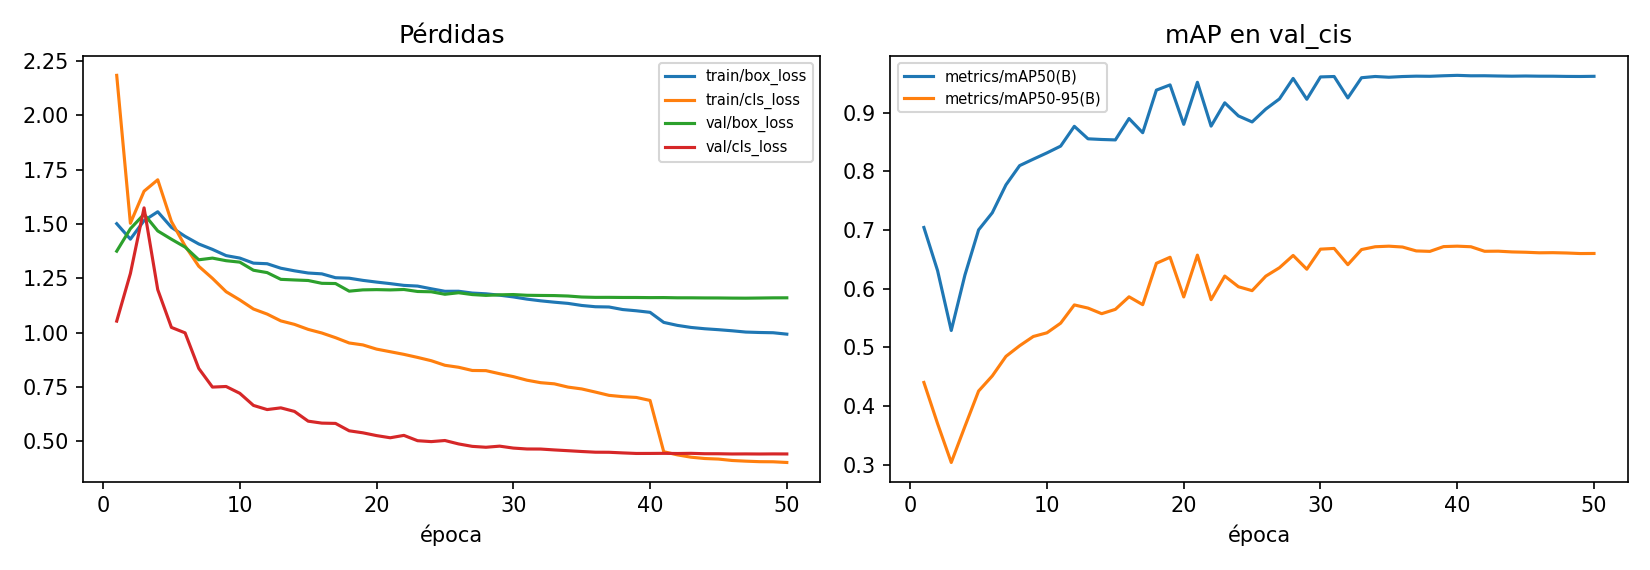

In [25]:
# Curvas de entrenamiento
from IPython.display import Image, display
png = entrenar.curvas(cfg, EXPERIMENTO)
if png: display(Image(str(png)))

In [26]:
# Cargar el mejor modelo
from ultralytics import YOLO
model = YOLO(str(BEST))
print("modelo cargado, clases:", len(model.names))

modelo cargado, clases: 15


## 5. Evaluación por partición y por especie (Tablas 2 y 3)
`val_cis` / `test_cis`: ubicaciones **vistas** en entrenamiento · `val_trans` / `test_trans`: ubicaciones **nuevas**. La brecha *cis − trans* mide la generalización a cámaras no vistas.

In [27]:
# 5. Evaluación
M, tab3, PC = evaluar.evaluar(cfg, model, EXPERIMENTO)

Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,131,389 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1949.1±544.9 MB/s, size: 90.5 KB)
val: Scanning /content/cct/yolo_data/labels/val_cis.cache... 2775 images, 220 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2775/2775 554.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 87/87 2.7it/s 32.1s
                   all       2775       2639      0.889      0.952      0.963      0.665
Speed: 0.9ms preprocess, 7.5ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to /content/drive/MyDrive/POSGRADO_IA/2026_2/REDES_NEURONALES/EXAMEN_PARCIAL/P03/resultados/runs/yolov8s_B_strong_eval_val_cis
Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,131,389 parameters, 0 gradients, 28.5 GFLOP

## 6. Robustez: tamaño y oclusión (Tabla 4)
CCT no anota oclusión: se usa un **indicador aproximado** (contraste de la caja contra un anillo de fondo + contacto con el borde). Es un proxy de camuflaje/oclusión parcial, no una medida directa.

In [28]:
# 6. Robustez
tab4, R = robustez.robustez(cfg, model, EXPERIMENTO)

Robustez sobre test_trans: 10027 imágenes (conf=0.25, IoU>=0.5 y misma clase = acierto)
  32/10027
  1632/10027
  3232/10027
  4832/10027
  6432/10027
  8032/10027
  9632/10027
Tabla 4 — recall por tamaño y oclusión (proxy):
                           n  recall
oclusion_proxy alto     4664   0.758
               bajo     2267   0.775
               medio    2917   0.841
tamano         pequeño   709   0.495
               mediano  7032   0.831
               grande   2107   0.736


## 7. Grad-CAM (Tabla 5)
Energía de atención dentro de las cajas reales y su enriquecimiento respecto al área (≈1 = sin preferencia por el animal). Se compara `val_cis` con `val_trans`.

  Grad-CAM val_cis: 100 imágenes
  Grad-CAM val_trans: 100 imágenes
Tabla 5 — Grad-CAM:
           energia_en_caja  fraccion_area  enriquecimiento
split                                                     
val_cis              0.066          0.066            1.040
val_trans            0.054          0.071            0.833


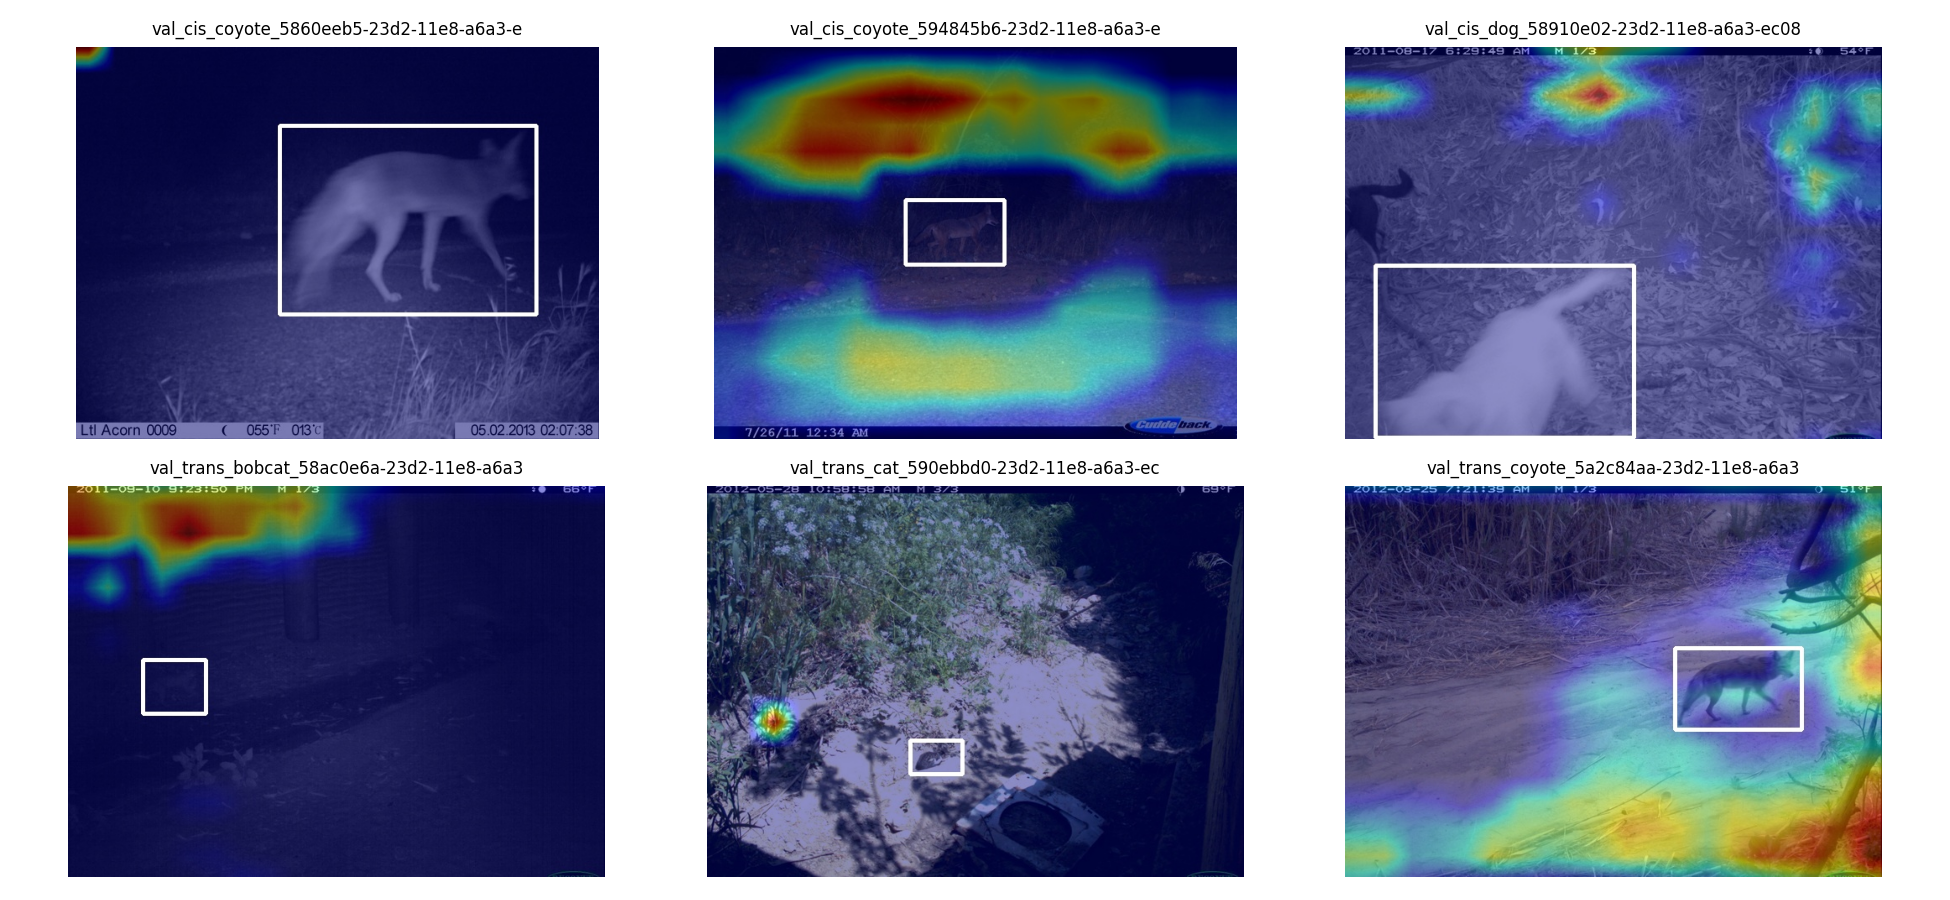

In [29]:
# 7. Grad-CAM
tab5 = gradcam_cct.gradcam_cct(cfg, BEST, EXPERIMENTO)
from IPython.display import Image, display
display(Image(str(cfg.RES / f"gradcam_galeria_{C.nombre_exp(cfg, EXPERIMENTO)}.png")))

## 8. Monitoreo ecológico (Tabla 6)
Sobre una cámara **no vista** (`test_trans`): detecciones por especie y periodo, y *eventos* (especie en ≥ `min_frames` fotogramas de una misma secuencia). Cambia `loc=` para otra cámara o `periodo=` (`"H"` hora, `"D"` día, `"M"` mes).

Cámara: 100 | imágenes: 4320
{'imagenes': 4320, 'con_fauna': 3948, 'vacias': 372, 'tasa_vacias': 0.086}
Tabla 6 — monitoreo por especie:
          detecciones  fotogramas  conf_media             primera  \
especie                                                             
raccoon          2342        2200       0.781 2010-05-25 23:48:14   
opossum           910         906       0.734 2010-05-25 20:32:56   
dog               493         366       0.791 2010-08-09 07:41:49   
cat               272         268       0.674 2010-05-25 20:32:57   
squirrel          138         136       0.647 2010-05-28 12:05:58   
rabbit            125         116       0.556 2010-06-07 21:34:52   
bird               70          59       0.488 2010-06-02 11:03:18   
bobcat             68          68       0.600 2010-07-06 04:50:33   
coyote             45          44       0.629 2010-08-13 10:08:22   
rodent              5           5       0.523 2010-10-16 04:13:44   
skunk               3           3  

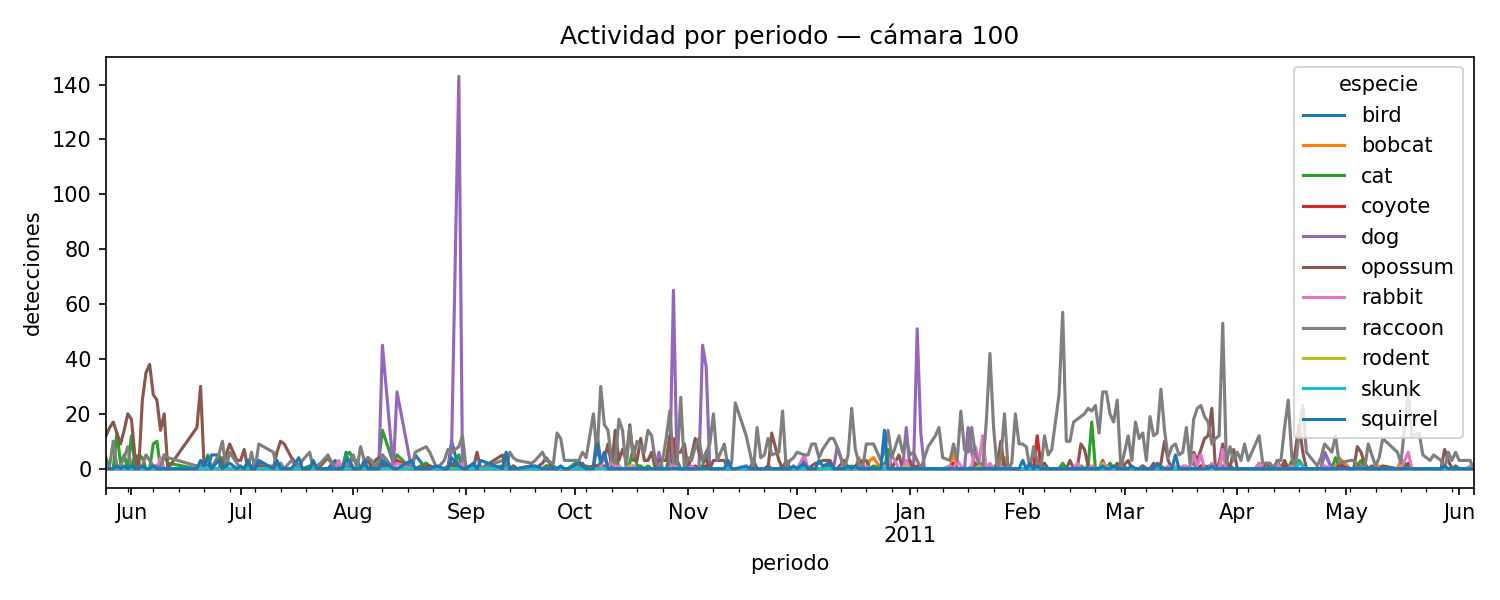

In [30]:
# 8. Monitoreo
tab6, act = monitoreo.monitoreo(cfg, model, EXPERIMENTO, split="test_trans", conf=0.25, min_frames=2, periodo="D", loc=None)
from IPython.display import Image, display
display(Image(str(cfg.RES / f"monitoreo_actividad_{C.nombre_exp(cfg, EXPERIMENTO)}.png")))